In [1]:
import os
import pickle
import runpy
import shutil
import subprocess
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from uncertainties import ufloat
from uncertainties import unumpy as unp
from caat.utils import WLE

In [2]:
from pathlib import Path
import os, sys
_cwd = Path.cwd()
_repo = (_cwd.parent if _cwd.name == "notebooks" else
         _cwd / "data_driven_bolometric_lc" if (_cwd / "data_driven_bolometric_lc").is_dir() else _cwd)
os.chdir(_repo)
for _path in (_repo, _repo / "run_files", _repo / "run_file", _repo.parent / "gopreaux" / "src"):
    if str(_path) not in sys.path: sys.path.insert(0, str(_path))


# Jacobson-Galan, SuperBol, and Gopreaux bolometric comparison

In [3]:
SN_NAME = "SN2013fs"
PHOTOMETRY_SOURCE = "JacobsonGalan"  # "JacobsonGalan" or "Gopreaux"
FILTERS = None
PHASE_MIN = 0
PHASE_MAX = 300
EBV_MW_ERR = 0.0  
PEAK_FIT_DEGREE = 3
PEAK_FIT_START_DAYS = 0.0
PEAK_FIT_END_DAYS = 30.0
PEAK_FIT_CENTER_DAYS = 15.0
max_mag_error  = 0.3

notebook_dir = Path.cwd()
if notebook_dir.name != "data_driven_bolometric_lc":
    notebook_dir = notebook_dir / "data_driven_bolometric_lc"

fit_choices_file = Path(notebook_dir / "run_files" / "superbol_fit_choices.py"
                         )
fit_choices_module = runpy.run_path(str(fit_choices_file))
fit_choices = fit_choices_module["SUPERBOL_FIT_CHOICES"]

source_fit_choices = (fit_choices if PHOTOMETRY_SOURCE == "JacobsonGalan"
                      else fit_choices_module["GOPREAUX_FIT_CHOICES"])
selected_fit_choice = source_fit_choices.get(SN_NAME)

data_dir = notebook_dir / "data"
repo_dir = notebook_dir.parent
superbol_script = repo_dir / "superbol" / "superbol.py"
run_label = (f"superbol_{SN_NAME}_JacobsonGalan_Gopreaux_run" if PHOTOMETRY_SOURCE == "JacobsonGalan"
             else f"superbol_{SN_NAME}_Gopreaux_input_run")
run_dir = notebook_dir / "output/superbol_jacobson_galan_gopreaux" / run_label

print("SN:", SN_NAME)
print("SuperBol photometry source:", PHOTOMETRY_SOURCE)


SN: SN2013fs
SuperBol photometry source: JacobsonGalan


## Read the data

In [4]:
# Published metadata provide distances, redshifts, and host reddening

metadata = pd.read_csv(data_dir / "Jacobson-Galan_typeII_SNe.csv")
match = metadata[metadata["SN name"].str.replace(" ", "").str.lower() == SN_NAME.replace(" ", "").lower()]
if len(match) != 1:
    raise ValueError(f"Found {len(match)} metadata rows for {SN_NAME}")
meta = match.iloc[0]
distance_mpc = float(meta["Distance_mpc"])
distance_err_mpc = float(meta["Distance_err_mpc"])
redshift = float(meta["Redshift"])
redshift_err = None if pd.isna(meta["Redshift_err"]) else float(meta["Redshift_err"])
first_light_mjd = float(meta["first_light_mjd"])
distance_with_error = ufloat(distance_mpc, distance_err_mpc)
distance_modulus_u = 5 * unp.log10(distance_with_error) + 25
distance_modulus = float(unp.nominal_values(distance_modulus_u))
distance_modulus_err = float(unp.std_devs(distance_modulus_u))

all_photometry = pd.read_csv(data_dir / "Jacobson_Galan_FMII_input_photometry.csv", low_memory=False)
jacobson_phot = all_photometry[all_photometry["sn"].str.replace(" ", "").str.lower()
                                == SN_NAME.replace(" ", "").lower()].copy()

if PHOTOMETRY_SOURCE == "JacobsonGalan":
    if jacobson_phot.empty:
        raise ValueError(f"No Jacobson-Galán photometry found for {SN_NAME}; choose Gopreaux")
    phot = jacobson_phot.copy()
    ebv_mw = float(phot["ebv_mw"].dropna().iloc[0])
else:
    from caat import SNCollection
    subtype = str(meta["Subtype"]).strip()
    collection = SNCollection(names=[SN_NAME], sntype=str(meta["Type"]), snsubtype=subtype)
    if len(collection.sne) != 1:
        raise ValueError(f"Gopreaux returned {len(collection.sne)} objects for {SN_NAME}")
    source_sn = collection.sne[0]
    cube_file = (Path(source_sn.base_path) / source_sn.classification / source_sn.subtype
                 / source_sn.name / f"{source_sn.name}_datacube_mangled.csv")
    if not cube_file.is_file():
        raise FileNotFoundError(f"Gopreaux photometry cube is missing: {cube_file}")
    cube = pd.read_csv(cube_file)
    phot = pd.DataFrame({
        "mjd": cube["MJD"], "magnitude": cube["Mag"],
        "magnitude_error": cube["Magerr"], "canonical_filter": cube["Filter"],
        "is_upper_limit": cube["Nondetection"], "facility": "Gopreaux",
        "source_file": str(cube_file),
    })
    ebv_mw = (float(jacobson_phot["ebv_mw"].dropna().iloc[0]) if not jacobson_phot.empty
              else float(source_sn.info.get("ebv_mw", 0.0)))

def first_detected_mjd(rows, max_mag_error=None):
    mjd = pd.to_numeric(rows["mjd"], errors="coerce")
    mag = pd.to_numeric(rows["magnitude"], errors="coerce")
    err = pd.to_numeric(rows["magnitude_error"], errors="coerce")
    upper_limit = rows["is_upper_limit"].astype(str).str.lower().isin(["true", "1", "yes"])
    usable = (~upper_limit) & mjd.notna() & mag.notna() & err.gt(0)
    if max_mag_error is not None:
        usable &= err.le(max_mag_error)
    if not usable.any():
        raise ValueError("No detected photometry is available to define phase zero")
    return float(mjd[usable].min())

# Use the first detection that passes the same magnitude-error cut as SuperBol.
phase_zero_mjd = first_detected_mjd(phot, max_mag_error=max_mag_error)
jacobson_first_observation_mjd = (
    first_detected_mjd(jacobson_phot, max_mag_error=max_mag_error)
    if not jacobson_phot.empty else None
)
phot["phase_observer_days"] = pd.to_numeric(phot["mjd"], errors="coerce") - phase_zero_mjd
original_phot = phot.copy()

host_reddening_text = str(meta["ebv_host"]).strip()
host_reddening_upper_limit = host_reddening_text.startswith("<")
ebv_host = float(host_reddening_text.lstrip("<").strip())
# No uncertainty is reported for upper limits; do not pass NaN errors to SuperBol.
ebv_host_err = 0.0 if pd.isna(meta["ebv_host_err"]) else float(meta["ebv_host_err"])
ebv_total_u = ufloat(ebv_mw, EBV_MW_ERR) + ufloat(ebv_host, ebv_host_err)
ebv_total = float(unp.nominal_values(ebv_total_u))
ebv_total_err = float(unp.std_devs(ebv_total_u))

with open(data_dir / "SNeII_bolometric_lcs_with_metadata_Jacobson-Galan.pkl", "rb") as f:
    bolometric_data = pickle.load(f)
literature_name = next((name for name in bolometric_data["lightcurves"]
                        if name.replace(" ", "").lower() == SN_NAME.replace(" ", "").lower()), None)
if literature_name is None:
    raise ValueError(f"No released bolometric light curve found for {SN_NAME}")
literature = bolometric_data["lightcurves"][literature_name]["data"].copy()
if jacobson_first_observation_mjd is None:
    jacobson_first_observation_mjd = (first_light_mjd +
        float(pd.to_numeric(literature["phase_days"], errors="coerce").min()))

print(f"Distance = {distance_mpc:.2f} ± {distance_err_mpc:.2f} Mpc")
print(f"Redshift = {redshift:g} ± {redshift_err:g}" if redshift_err is not None
      else f"Redshift = {redshift:g} (error not reported)")
print(f"Distance modulus = {distance_modulus:.3f} ± {distance_modulus_err:.3f} mag")
print(f"First light = MJD {first_light_mjd:.3f}; {PHOTOMETRY_SOURCE} first detection = MJD {phase_zero_mjd:.3f}")
print(f"Jacobson-Galán first observation = MJD {jacobson_first_observation_mjd:.3f}")
print(f"E(B-V): MW {ebv_mw:.3f} (error unavailable), host {ebv_host:.3f} ± {ebv_host_err:.3f}")
if host_reddening_upper_limit:
    print("Host reddening is an upper limit; its uncertainty is unavailable and not propagated.")
print(f"Photometry rows = {len(phot)}")

Distance = 50.60 ± 0.90 Mpc
Redshift = 0.012 (error not reported)
Distance modulus = 33.521 ± 0.039 mag
First light = MJD 56571.110; JacobsonGalan first detection = MJD 56571.415
Jacobson-Galán first observation = MJD 56571.415
E(B-V): MW 0.035 (error unavailable), host 0.020 ± 0.004
Photometry rows = 407


## Prepare AB absolute magnitudes

In [5]:
filter_map = {
    "UVW2": "S", "UVM2": "D", "UVW1": "A",
    "u": "u", "U": "U", "B": "B", "V": "V",
    "g": "g", "r": "r", "i": "i", "z": "z", "y": "y",
    "c": "c", "o": "o", "w": "w", "R": "R", "I": "I", "Y": "Y",
    "J": "J", "H": "H", "K": "K", "Ks": "K"
}
# Coefficients A_lambda / E(B-V), from superbol/superbol.py (extco)
extco = {
    "u": 4.786, "g": 3.587, "r": 2.471, "i": 1.798, "z": 1.403,
    "y": 1.228, "w": 2.762, "Y": 1.228, "U": 4.744, "B": 4.016,
    "V": 3.011, "R": 2.386, "I": 1.684, "J": 0.813, "H": 0.516,
    "K": 0.337, "S": 8.795, "D": 9.270, "A": 6.432,
    "o": 2.185, "c": 3.111
}

for column in ["phase_observer_days", "magnitude", "magnitude_error", "mjd"]:
    phot[column] = pd.to_numeric(phot[column], errors="coerce")
upper_limit = phot["is_upper_limit"].astype(str).str.lower().isin(["true", "1", "yes"])
phot = phot[(~upper_limit) & phot["phase_observer_days"].between(PHASE_MIN, PHASE_MAX)
            & phot["magnitude"].notna() & phot["magnitude_error"].gt(0) & phot["magnitude_error"].le(0.3)
            & phot["mjd"].notna()].copy()

phot["filter"] = phot["canonical_filter"].astype(str)
is_swift = (phot["facility"].astype(str).str.contains("Swift|UVOT", case=False, regex=True)
            | phot["source_file"].astype(str).str.contains("swift", case=False))
phot.loc[is_swift, "filter"] = phot.loc[is_swift, "filter"].replace({"b": "B", "v": "V"})
phot = phot[phot["filter"].isin(filter_map)].copy()
phot["superbol_filter"] = phot["filter"].map(filter_map)
phot["R_lambda"] = phot["superbol_filter"].map(extco)
if phot["R_lambda"].isna().any():
    raise ValueError("Missing extinction coefficient for selected filter")

    
# R_v_replacement = np.ones_like(phot["R_lambda"])*3.1

phot["phase_used_days"] = phot["mjd"] - phase_zero_mjd
observed_magnitude_u = unp.uarray(
    phot["magnitude"].to_numpy(dtype=float),
    phot["magnitude_error"].to_numpy(dtype=float),
)
phot["absolute_magnitude_u"] = (
    observed_magnitude_u - distance_modulus_u
    - phot["R_lambda"].to_numpy(dtype=float) * ebv_total_u
)

# Alternate correction using Jacobson-Galan's Fitzpatrick99 law at each
# filter's effective wavelength. A_lambda is linear in E(B-V) for fixed R_V.
import extinction
f99_r_lambda = {band: float(extinction.fitzpatrick99(
    np.array([WLE[band]]), 3.1, r_v=3.1, unit="aa")[0])
    for band in phot["filter"].unique()}
phot["absolute_magnitude_f99_u"] = (
    observed_magnitude_u - distance_modulus_u
    - phot["filter"].map(f99_r_lambda).to_numpy(dtype=float)
    * ufloat(ebv_mw, EBV_MW_ERR)
    - phot["filter"].map(f99_r_lambda).to_numpy(dtype=float)
    * ufloat(ebv_host, ebv_host_err)
)


phot = phot.groupby(["superbol_filter", "mjd"], as_index=False).agg(
    phase_used_days=("phase_used_days", "mean"),
    absolute_magnitude_u=("absolute_magnitude_u", lambda values: sum(values) / len(values)),
    absolute_magnitude_f99_u=("absolute_magnitude_f99_u", lambda values: sum(values) / len(values)),
)
phot["absolute_magnitude"] = unp.nominal_values(phot["absolute_magnitude_u"].to_numpy())
phot["absolute_magnitude_error"] = unp.std_devs(phot["absolute_magnitude_u"].to_numpy())
phot["absolute_magnitude_f99"] = unp.nominal_values(phot["absolute_magnitude_f99_u"].to_numpy())
phot["absolute_magnitude_f99_error"] = unp.std_devs(phot["absolute_magnitude_f99_u"].to_numpy())
phot = phot.drop(columns=["absolute_magnitude_u", "absolute_magnitude_f99_u"])
counts = phot.groupby("superbol_filter").size().sort_values(ascending=False)
counts = counts[counts >= 2]  # SuperBol needs at least two epochs per filter.
selected_filters = counts.index.tolist() if FILTERS is None else [filter_map.get(name, name) for name in FILTERS]
# The recorded interpolation plan also defines the intended band set.
if selected_fit_choice:
    planned_filters = set(selected_fit_choice["bands"]) | {selected_fit_choice["reference_filter"]}
    selected_filters = [band for band in selected_filters if band in planned_filters]
if len(selected_filters) < 2:
    raise ValueError("SuperBol needs at least two filters")
phot = phot[phot["superbol_filter"].isin(selected_filters)].copy()
# Select the reference band whose epochs best match the released bolometric epochs.
released_phases = pd.to_numeric(literature["phase_days"], errors="coerce").dropna().to_numpy()
def reference_match_score(band):
    epochs = phot.loc[phot["superbol_filter"] == band, "phase_used_days"].to_numpy()
    nearest = np.min(np.abs(released_phases[:, None] - epochs[None, :]), axis=1)
    return (int(np.count_nonzero(nearest < 0.1)), -float(np.median(nearest)), len(epochs))
reference_filter = (selected_fit_choice["reference_filter"] if selected_fit_choice and selected_fit_choice["reference_filter"] in selected_filters
                    else max(selected_filters, key=reference_match_score))
if reference_filter not in selected_filters:
    raise ValueError(f"Configured reference filter {reference_filter} is unavailable for {SN_NAME}")
reference_filter_peak = reference_filter

reference_hits = reference_match_score(reference_filter)[0]
reference_rows = phot["superbol_filter"].eq(reference_filter)
reference_epoch_delta = np.min(
    np.abs(phot.loc[reference_rows, "phase_used_days"].to_numpy()[:, None]
           - released_phases[None, :]), axis=1)
matching_reference_index = phot.loc[reference_rows].index[reference_epoch_delta < 0.005]
if PHOTOMETRY_SOURCE == "JacobsonGalan" and len(matching_reference_index) / len(released_phases) >= 0.9:
    phot = phot.loc[~reference_rows | phot.index.isin(matching_reference_index)].copy()
    print(f"Reference epochs retained: {len(matching_reference_index)} published matches")
remaining_counts = phot.groupby("superbol_filter").size()
selected_filters = [band for band in selected_filters if remaining_counts.get(band, 0) >= 2]
if reference_filter not in selected_filters:
    raise ValueError("Timestamp-matched reference band has fewer than two retained points")
phot = phot[phot["superbol_filter"].isin(selected_filters)].copy()

def peak_fit_is_supported(band):
    early = phot[(phot["superbol_filter"] == band)
                 & phot["phase_used_days"].between(PEAK_FIT_START_DAYS, PEAK_FIT_END_DAYS)]
    if len(early) < PEAK_FIT_DEGREE + 3:
        return False
    x = early["phase_used_days"].to_numpy() - PEAK_FIT_CENTER_DAYS
    y = early["absolute_magnitude"].to_numpy()
    sigma = early["absolute_magnitude_error"].to_numpy()
    if not (np.isfinite(x).all() and np.isfinite(y).all()
            and np.isfinite(sigma).all() and (sigma > 0).all()):
        return False
    polynomial = np.poly1d(np.polyfit(x, y, PEAK_FIT_DEGREE, w=1 / sigma))
    return any(abs(root.imag) < 1e-8 and x.min() < root.real < x.max()
               and np.polyder(polynomial, 2)(root.real) > 0
               for root in np.roots(np.polyder(polynomial)))

if not peak_fit_is_supported(reference_filter_peak):
    candidates = [band for band in selected_filters if peak_fit_is_supported(band)]
    if candidates:
        reference_filter_peak = max(candidates, key=lambda band: (
            phot[phot["superbol_filter"] == band]["phase_used_days"].between(
                PEAK_FIT_START_DAYS, PEAK_FIT_END_DAYS).sum(),
            reference_match_score(band)))
        print(f"Peak-fit band: {reference_filter_peak}; SuperBol reference remains {reference_filter}")
if PHOTOMETRY_SOURCE == "Gopreaux" and selected_fit_choice is None:
    gopreaux_fit_choice = fit_choices_module["gopreaux_fit_choice"]
    band_epochs = {band: group["mjd"].tolist()
                   for band, group in phot.groupby("superbol_filter")}
    selected_fit_choice = gopreaux_fit_choice(band_epochs, reference_filter)
    print("Generated Gopreaux fit choices from available band coverage")
superbol_order = "".join(b for b in "FSDNAuUBgcVwrRoGEiIzyYJHKWQ" if b in selected_filters)
print("Selected filters:", selected_filters)
print("SuperBol filter order:", superbol_order)
print(f"Reference filter: {reference_filter} ({reference_hits}/{len(released_phases)} released epochs within 0.1 d)")
print("First detected observation MJD:", phase_zero_mjd)

Selected filters: ['U', 'i', 'V', 'g', 'z', 'r', 'R', 'I', 'A', 'D', 'S']
SuperBol filter order: SDAUgVrRiIz
Reference filter: i (1/40 released epochs within 0.1 d)
First detected observation MJD: 56571.41510603993


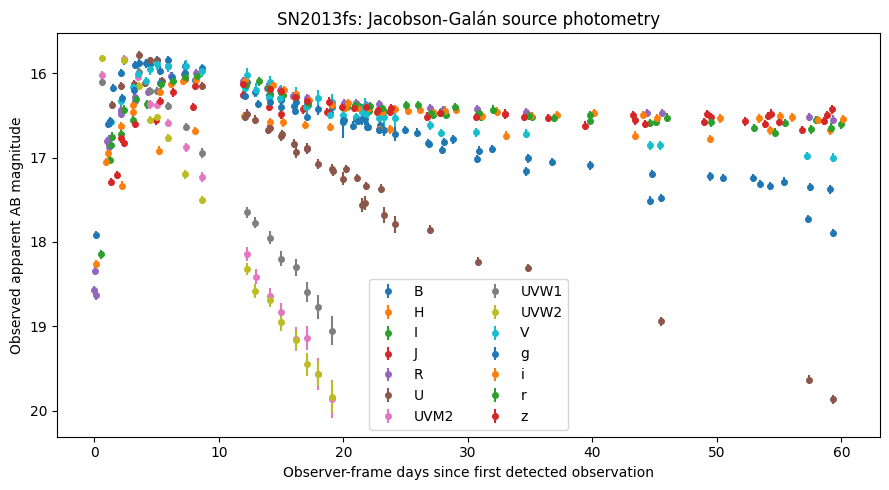

In [6]:
source_phot = original_phot.copy()
for column in ["mjd", "magnitude", "magnitude_error"]:
    source_phot[column] = pd.to_numeric(source_phot[column], errors="coerce")
source_upper_limit = source_phot["is_upper_limit"].astype(str).str.lower().isin(["true", "1", "yes"])
source_phot = source_phot[(~source_upper_limit)
                          & source_phot["mjd"].notna()
                          & source_phot["magnitude"].notna()
                          & source_phot["magnitude_error"].gt(0)
                          & source_phot["magnitude_error"].le(0.3)].copy()
source_phot["phase_used_days"] = source_phot["mjd"] - phase_zero_mjd
source_phot = source_phot[source_phot["phase_used_days"].between(PHASE_MIN, PHASE_MAX)]
source_phot["source_band"] = source_phot["canonical_filter"].astype(str)
source_is_swift = (source_phot["facility"].astype(str).str.contains("Swift|UVOT", case=False, regex=True)
                   | source_phot["source_file"].astype(str).str.contains("swift", case=False))
source_phot.loc[source_is_swift, "source_band"] = source_phot.loc[source_is_swift, "source_band"].replace({"b": "B", "v": "V"})

fig, ax = plt.subplots(figsize=(9, 5))
for band, band_data in source_phot.groupby("source_band", sort=True):
    ax.errorbar(band_data["phase_used_days"], band_data["magnitude"],
                yerr=band_data["magnitude_error"], fmt="o", ms=4, label=band)
ax.invert_yaxis()
ax.set_xlabel("Observer-frame days since first detected observation")
ax.set_ylabel("Observed apparent AB magnitude")
ax.set_title(f"{SN_NAME}: Jacobson-Galán source photometry")
ax.legend(ncol=2)
fig.tight_layout()
plt.show()


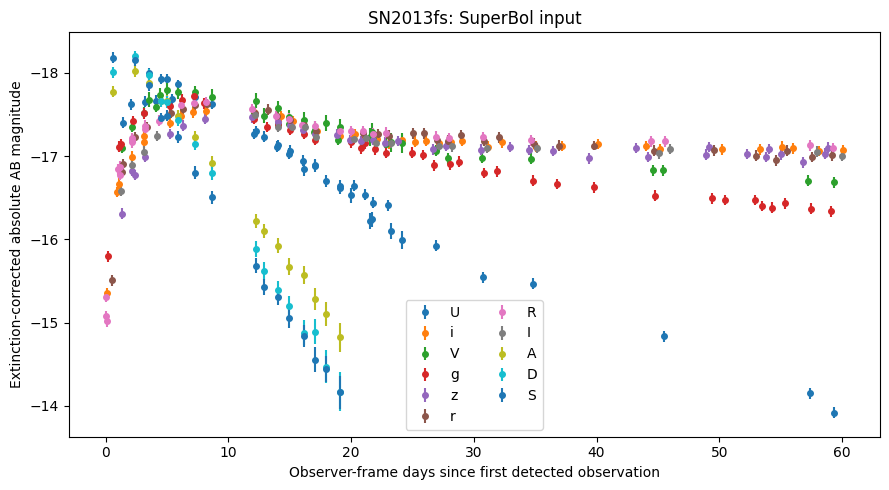

In [7]:
plt.figure(figsize=(9, 5))
for band in selected_filters:
    band_data = phot[phot["superbol_filter"] == band]
    plt.errorbar(band_data["phase_used_days"], band_data["absolute_magnitude"],
                 yerr=band_data["absolute_magnitude_error"], fmt="o", ms=4, label=band)
plt.gca().invert_yaxis()
plt.xlabel("Observer-frame days since first detected observation")
plt.ylabel("Extinction-corrected absolute AB magnitude")
plt.title(f"{SN_NAME}: SuperBol input")
plt.legend(ncol=2)
plt.tight_layout()
plt.show()

## Polynomial fit to the reference-band peak

In [8]:
# fit_start_days = PEAK_FIT_START_DAYS
# fit_end_days = PEAK_FIT_END_DAYS
# fit_center = PEAK_FIT_CENTER_DAYS

# reference_data = phot[phot["superbol_filter"] == reference_filter_peak].sort_values("phase_used_days")
# t_ref = reference_data["phase_used_days"].to_numpy()
# m_ref = reference_data["absolute_magnitude"].to_numpy()
# sigma_ref = reference_data["absolute_magnitude_error"].to_numpy()

# fit_mask = ((t_ref >= fit_start_days) & (t_ref <= fit_end_days)
#             & np.isfinite(t_ref) & np.isfinite(m_ref)
#             & np.isfinite(sigma_ref) & (sigma_ref > 0))
# if fit_mask.sum() < PEAK_FIT_DEGREE + 3:
#     raise ValueError(f"Only {fit_mask.sum()} reference-band points in the {fit_start_days:g}–{fit_end_days:g} day fit window")

# coefficients = np.polyfit(
#     t_ref[fit_mask] - fit_center,
#     m_ref[fit_mask],
#     deg=PEAK_FIT_DEGREE,
#     w=1 / sigma_ref[fit_mask],
# )

# fit_phase = np.linspace(t_ref[fit_mask].min(), t_ref[fit_mask].max(), 2001)
# fit_magnitude = np.polyval(coefficients, fit_phase - fit_center)


# polynomial = np.poly1d(coefficients)
# stationary = np.roots(np.polyder(polynomial))
# peak_candidates = [float(root.real + fit_center) for root in stationary
#                    if abs(root.imag) < 1e-8
#                    and fit_phase.min() < root.real + fit_center < fit_phase.max()
#                    and np.polyder(polynomial, 2)(root.real) > 0]
# if not peak_candidates:
#     raise ValueError("No interior brightness peak in the selected polynomial fit window")
# peak_phase_days = min(peak_candidates, key=lambda day: polynomial(day - fit_center))
# peak_mjd = phase_zero_mjd + peak_phase_days

# fig, ax = plt.subplots(figsize=(8, 4))
# ax.errorbar(t_ref, m_ref, yerr=sigma_ref, fmt="o", ms=3, alpha=0.55, label="Reference photometry")
# ax.plot(fit_phase, fit_magnitude, color="tab:red", label="Weighted polynomial")
# ax.axvline(peak_phase_days, color="tab:red", ls="--", label=f"Peak {peak_phase_days:.2f} d")
# ax.set_xlim(fit_phase.min() - 2, fit_phase.max() + 2)
# ax.invert_yaxis()
# ax.set_xlabel("Observer-frame days since first detected observation")
# ax.set_ylabel("Absolute AB magnitude")
# ax.set_title(f"{SN_NAME}: {reference_filter_peak}-band peak fit")
# ax.legend()
# fig.tight_layout()
# run_dir.mkdir(parents=True, exist_ok=True)
# peak_figure_file = run_dir / f"{SN_NAME}_{reference_filter_peak}_peak_polynomial_fit.png"
# fig.savefig(peak_figure_file, dpi=180)
# plt.show()


In [9]:
# Photometric coverage relative to the first detected observation:
band_coverage = phot.groupby("superbol_filter").agg(
    n_epochs=("mjd", "size"),
    first_mjd=("mjd", "min"),
    last_mjd=("mjd", "max"),
)
band_coverage["first_day_from_observation"] = band_coverage["first_mjd"] - phase_zero_mjd
band_coverage["last_day_from_observation"] = band_coverage["last_mjd"] - phase_zero_mjd

## Make the SuperBol input file

In [10]:
# SuperBol expects: phase, magnitude, error for each filter in wavelength order.
# Shift phases to the polynomial peak; SuperBol itself will not shift them again.

run_dir.mkdir(parents=True, exist_ok=True)
phot["phase_from_first_observation_days"] = phot["mjd"] - phase_zero_mjd
phase_grid = np.sort(phot["phase_from_first_observation_days"].unique())
superbol_input = pd.DataFrame({"phase": phase_grid})
for band in superbol_order:
    band_data = phot[phot["superbol_filter"] == band].set_index("phase_from_first_observation_days")
    superbol_input[band] = superbol_input["phase"].map(band_data["absolute_magnitude"])
    superbol_input[band + "_error"] = superbol_input["phase"].map(band_data["absolute_magnitude_error"])

input_file = run_dir / f"{SN_NAME}_{superbol_order}.txt"
np.savetxt(input_file, superbol_input.values, fmt="%.8f")

# Same epochs and band order, with only the extinction law changed.
run_dir_f99 = run_dir / "superbol_fitzpatrick99"
run_dir_f99.mkdir(exist_ok=True)
superbol_input_f99 = pd.DataFrame({"phase": phase_grid})
for band in superbol_order:
    band_data = phot[phot["superbol_filter"] == band].set_index("phase_from_first_observation_days")
    superbol_input_f99[band] = superbol_input_f99["phase"].map(band_data["absolute_magnitude_f99"])
    superbol_input_f99[band + "_error"] = superbol_input_f99["phase"].map(
        band_data["absolute_magnitude_f99_error"])
input_file_f99 = run_dir_f99 / input_file.name
np.savetxt(input_file_f99, superbol_input_f99.values, fmt="%.8f")


## Run SuperBol

### SuperBol interpolation choices

In [11]:
old_output_dir = run_dir / f"superbol_output_{SN_NAME}"

answers = [
    SN_NAME,
    "n",              # do not auto-discover files
    input_file.name,
    "",               # no further phase cut
    "",               # all filters
    reference_filter,
    "n",              # do not shift the light-curve maximum
    "0",              # no redshift/distance conversion: input already absolute
    "n",              # retain observer-frame phases (no dilation correction)
    "y",              # absolute magnitudes: SuperBol uses 10 pc
    "y" if selected_fit_choice else "n",  # recorded interactive polynomial fits
    "0",              # extinction already corrected in absolute magnitudes
    "n",              # specify system for each band
    *["A" for _ in superbol_order],  # all released magnitudes are AB
    "n",              # skip approximate K correction (no filter shifts)
    "n",              # no UV suppression in internal BB fit
    "10000",          # internal BB initial temperature guess (Lbb unused)
    "1e15",           # internal BB initial radius guess (Lbb unused)
    ""
]










# Checking if the selected_fit_choice per SN is valid

if selected_fit_choice:
    fitted_bands = set(superbol_order) - {reference_filter}
    fit_plan = {band: choice for band, choice in selected_fit_choice["bands"].items()
                if band in fitted_bands}
    if set(fit_plan) != fitted_bands:
        raise ValueError(f"Fit-plan bands differ from selected non-reference bands: "
                         f"missing={sorted(fitted_bands - set(fit_plan))}, "
                         f"extra={sorted(set(fit_plan) - fitted_bands)}")
    ref_epochs = phot.loc[phot["superbol_filter"].eq(reference_filter), "phase_from_first_observation_days"]
    fit_answers = []
    for band in superbol_order:
        if band == reference_filter:
            continue
        order, early_method, late_method = fit_plan[band]
        if order == "q":
            # SuperBol uses linear interpolation and constant-colour extrapolation.
            # It asks no fit-approval or extrapolation questions for this band.
            fit_answers.append("q")
            continue
        band_rows = phot.loc[phot["superbol_filter"].eq(band)]
        band_epochs = band_rows["phase_from_first_observation_days"]
        need_early = band_epochs.min() > ref_epochs.min()
        need_late = band_epochs.max() < ref_epochs.max()
        # The recorded plan describes the original input coverage. Recompute
        # which prompts this particular source and phase selection will ask.
        order = min(order if order is not None else 2, len(band_epochs) - 1)
        early_method = (early_method or "c") if need_early else None
        late_method = (late_method or "c") if need_late else None
        if need_early and early_method not in {"p", "c", "a"}:
            raise ValueError(f"{band}: early extrapolation must be p, c, or a")
        if need_late and late_method not in {"p", "c", "a"}:
            raise ValueError(f"{band}: late extrapolation must be p, c, or a")
        if not need_early and early_method is not None:
            raise ValueError(f"{band}: no early extrapolation prompt is expected")
        if not need_late and late_method is not None:
            raise ValueError(f"{band}: no late extrapolation prompt is expected")
        if need_late and late_method in {"p", "a"}:
            coefficients = np.polyfit(band_epochs, band_rows["absolute_magnitude"], order)
            predicted = np.polyval(coefficients, ref_epochs)
            if not np.isfinite(predicted).all() or predicted.min() < -35:
                raise ValueError(
                    f"{band}: order-{order} extrapolation becomes non-finite or "
                    "unphysically bright; lower the order or choose late constant colour")
        fit_answers.extend([str(order), "y"])
        if need_early:
            fit_answers.append(early_method)
        if need_late:
            fit_answers.append(late_method)
    # The interpolation prompt is entry 10; subsequent questions start at 11.
    answers = answers[:11] + fit_answers + answers[11:]
    
    
# Validate the complete fit plan before replacing any saved SuperBol output.
if old_output_dir.exists():
    shutil.rmtree(old_output_dir)
environment = os.environ.copy()
environment["MPLBACKEND"] = "Agg"
result = subprocess.run([sys.executable, str(superbol_script)],
                        input="\n".join(answers) + "\n", text=True,
                        cwd=run_dir, env=environment,
                        capture_output=True, timeout=600)
(run_dir / "superbol_stdout.txt").write_text(result.stdout + result.stderr)
if result.returncode != 0:
    print(result.stdout[-3000:])
    print(result.stderr[-3000:])
    raise RuntimeError("SuperBol did not finish successfully")
output_file = old_output_dir / f"bol_{SN_NAME}_{superbol_order}.txt"
if not output_file.is_file():
    raise FileNotFoundError(output_file)
print("SuperBol finished successfully")

old_output_dir_f99 = run_dir_f99 / f"superbol_output_{SN_NAME}"
if old_output_dir_f99.exists():
    shutil.rmtree(old_output_dir_f99)
result_f99 = subprocess.run([sys.executable, str(superbol_script)],
                            input="\n".join(answers) + "\n", text=True,
                            cwd=run_dir_f99, env=environment,
                            capture_output=True, timeout=600)
(run_dir_f99 / "superbol_stdout.txt").write_text(result_f99.stdout + result_f99.stderr)
if result_f99.returncode != 0:
    print(result_f99.stdout[-3000:])
    print(result_f99.stderr[-3000:])
    raise RuntimeError("Fitzpatrick99 SuperBol run did not finish successfully")
output_file_f99 = old_output_dir_f99 / f"bol_{SN_NAME}_{superbol_order}.txt"
if not output_file_f99.is_file():
    raise FileNotFoundError(output_file_f99)
print("Fitzpatrick99 SuperBol finished successfully")

SuperBol finished successfully
Fitzpatrick99 SuperBol finished successfully


## Compare pseudo-bolometric light curves

In [12]:
expected_output = run_dir / f"superbol_output_{SN_NAME}" / f"bol_{SN_NAME}_{superbol_order}.txt"
expected_output_f99 = (run_dir_f99 / f"superbol_output_{SN_NAME}"
                       / f"bol_{SN_NAME}_{superbol_order}.txt")
if Path(output_file).resolve() != expected_output.resolve() or not expected_output.is_file():
    raise RuntimeError(f"Run SuperBol for {SN_NAME} before loading Lobs: {expected_output}")
if Path(output_file_f99).resolve() != expected_output_f99.resolve() or not expected_output_f99.is_file():
    raise RuntimeError(f"Run Fitzpatrick99 SuperBol for {SN_NAME} before loading Lobs: {expected_output_f99}")

values = np.atleast_2d(np.loadtxt(output_file))
superbol_lc = pd.DataFrame(values, columns=["phase", "Lobs", "Lobs_error", "Lbb", "Lbb_error"])
values_f99 = np.atleast_2d(np.loadtxt(output_file_f99))
superbol_lc_f99 = pd.DataFrame(
    values_f99, columns=["phase", "Lobs", "Lobs_error", "Lbb", "Lbb_error"])
if not np.allclose(superbol_lc_f99["phase"], superbol_lc["phase"]):
    raise ValueError("SuperBol extinction runs have different phase grids")
for column in ["phase_days", "bol_lum_erg_s", "bol_lum_err_erg_s"]:
    literature[column] = pd.to_numeric(literature[column], errors="coerce")
literature = literature.dropna(subset=["phase_days", "bol_lum_erg_s"]).sort_values("phase_days")
literature["phase_from_first_observation_days"] = (
    literature["phase_days"] + first_light_mjd - jacobson_first_observation_mjd)

inside = superbol_lc["phase"].between(literature["phase_from_first_observation_days"].min() - 0.005,
                                        literature["phase_from_first_observation_days"].max() + 0.005)
comparison = superbol_lc[inside].copy()
comparison["literature_Lbol"] = np.interp(
    comparison["phase"], literature["phase_from_first_observation_days"], literature["bol_lum_erg_s"])
comparison["difference_dex"] = np.log10(comparison["Lobs"]) - np.log10(comparison["literature_Lbol"])
if comparison.empty:
    raise ValueError("No overlapping phases between SuperBol and released curve")
median_difference = comparison["difference_dex"].median()
rmse = np.sqrt(np.mean(comparison["difference_dex"]**2))


## Gopreaux bolometric light curve

In [13]:
from astropy import units as u
from caat import DataCube, SNCollection, SNModel
from caat.utils import WLE


collection = SNCollection(names=[SN_NAME], sntype=str(meta["Type"]), snsubtype="SNII") 
    
gopreaux_sn = collection.sne[0]
a_v = float(ebv_host) * 3.1
cube = DataCube(sn=gopreaux_sn, a_v=a_v)
cube.measure_flux_in_filter(overwrite=True, save=True)

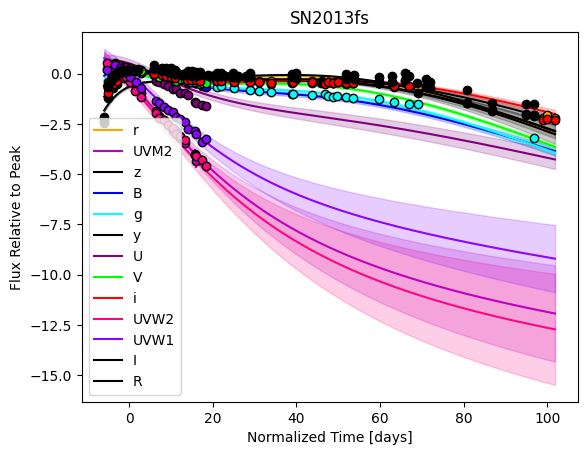

In [14]:
subtype = str(meta["Subtype"]).strip()
model_subtype = "SNIIP" if subtype == "SNIIP" else "SNII"
if subtype not in {"SNIIP", "SNII", "SNII-pec"}:
    raise ValueError(f"No saved SNIIP/SNII model mapping for subtype {subtype!r}")
saved_model_file = repo_dir / "gopreaux" / "data" / "final_models" / f"SNII_{model_subtype}_GP_model.fits"

gopreaux_model = SNModel(surface=str(saved_model_file))
gopreaux_model.fit_photometry(sn_to_fit=gopreaux_sn, show=False,
                              nsamples=1, keep_new_fit=True)

In [15]:
zp_peak = gopreaux_sn.zps[gopreaux_sn.info["peak_filt"]]
f_peak_ref = zp_peak * 10**(-0.4 * gopreaux_sn.info["peak_mag"])
f_peak_ref_log = np.log10(f_peak_ref)

# Stay just inside the phase and wavelength bounds of the model.
phase_min = gopreaux_model.min_phase + 1
phase_max = gopreaux_model.max_phase - 1
phase_step = 2
phases = np.arange(phase_min, phase_max + phase_step, phase_step)

F_bol = np.zeros(len(phases))
F_up = np.zeros(len(phases))
F_low = np.zeros(len(phases))

wavelength_min = gopreaux_model.min_wl + 1
wavelength_max = gopreaux_model.max_wl - 1

In [16]:
print('Predicting SED per phase grid using Gopreaux.')
for ph, phase in enumerate(phases):
    x, shifted_flux, sigma = gopreaux_model.predict_sed(
        wavelength_min=wavelength_min,
        wavelength_max=wavelength_max,
        phase=phase,
        show=False,
    )

    valid = (
        np.isfinite(x)
        & np.isfinite(shifted_flux)
        & np.isfinite(sigma)
    )
    x = x[valid]
    shifted_flux = shifted_flux[valid]
    sigma = sigma[valid]

    if len(x) < 2:
        F_bol[ph] = np.nan
        F_up[ph] = np.nan
        F_low[ph] = np.nan
        continue

    f_lambda = 10**(shifted_flux + f_peak_ref_log)
    f_lambda_upper = 10**(shifted_flux + f_peak_ref_log + sigma)
    f_lambda_lower = 10**(shifted_flux + f_peak_ref_log - sigma)

    F_bol[ph] = np.trapezoid(f_lambda, x)
    F_up[ph] = np.trapezoid(f_lambda_upper, x)
    F_low[ph] = np.trapezoid(f_lambda_lower, x)

Predicting SED per phase grid using Gopreaux.


In [17]:
bol_lc_all = {}

d_L = distance_mpc * u.Mpc.to(u.cm)

L_bol = 4 * np.pi * d_L**2 * F_bol
L_bol_up = 4 * np.pi * d_L**2 * F_up
L_bol_low = 4 * np.pi * d_L**2 * F_low

bol_lc_all[SN_NAME] = {}
bol_lc_all[SN_NAME]['L_bol'] = L_bol
bol_lc_all[SN_NAME]['L_bol_upper'] = L_bol_up
bol_lc_all[SN_NAME]['L_bol_lower'] = L_bol_low
bol_lc_all[SN_NAME]['phases'] = phases

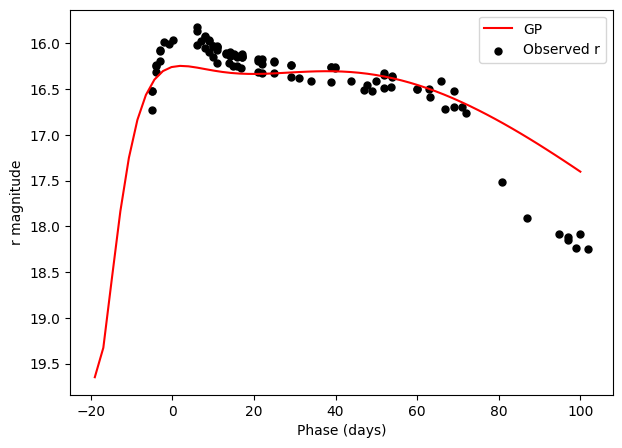

In [18]:
# Check GP light curve prediction versus observations for one band
band = "r"

phs, shifted_mag, sigma = gopreaux_model.predict_lightcurve(
    phase_min=-19,
    phase_max=100,             
    wavelength=WLE[band],
    show=False,
)

mag_pred = gopreaux_sn.info["peak_mag"] - shifted_mag

vdata = gopreaux_sn.cube[
    gopreaux_sn.cube["ShiftedFilter"] == band
]

plt.figure(figsize=(7, 5))
plt.plot(phs, mag_pred, "r-", label="GP")
plt.scatter(
    vdata["Phase"],
    vdata["Mag"],
    color="k",
    s=25,
    label=f"Observed {band}",
)
plt.gca().invert_yaxis()
plt.xlabel("Phase (days)")
plt.ylabel(f"{band} magnitude")
plt.legend()

In [19]:
gopreaux_t_shift =  gopreaux_sn.info['peak_mjd'] - first_light_mjd

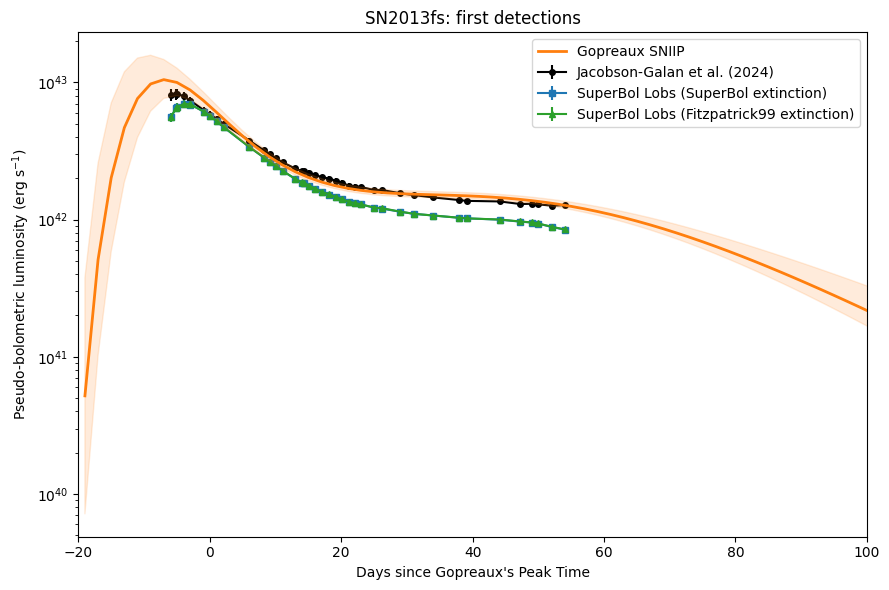

In [22]:
fig, ax = plt.subplots(figsize=(9, 6))
ax.errorbar(literature["phase_from_first_observation_days"]-gopreaux_t_shift, literature["bol_lum_erg_s"],
            yerr=literature["bol_lum_err_erg_s"], fmt="o-", color="black",
            ms=4, label="Jacobson-Galan et al. (2024)")
ax.errorbar(superbol_lc["phase"]-gopreaux_t_shift, superbol_lc["Lobs"],
            yerr=superbol_lc["Lobs_error"], fmt="s-", color="tab:blue",
            ms=4, label="SuperBol Lobs (SuperBol extinction)")
ax.errorbar(superbol_lc_f99["phase"]-gopreaux_t_shift, superbol_lc_f99["Lobs"],
            yerr=superbol_lc_f99["Lobs_error"], fmt="^-", color="tab:green",
            ms=4, label="SuperBol Lobs (Fitzpatrick99 extinction)")
ax.plot(bol_lc_all[SN_NAME]['phases'], bol_lc_all[SN_NAME]['L_bol'],
        color="tab:orange", lw=2, label=f"Gopreaux {model_subtype}", zorder=11)
ax.fill_between(bol_lc_all[SN_NAME]['phases'], bol_lc_all[SN_NAME]['L_bol_lower'],
                bol_lc_all[SN_NAME]['L_bol_upper'], color="tab:orange", alpha=0.15, zorder=18)

ax.set_yscale("log")
ax.set_xlabel("Days since Gopreaux's Peak Time")
ax.set_ylabel(r"Pseudo-bolometric luminosity (erg s$^{-1}$)")
ax.set_title(f"{SN_NAME}: first detections")
ax.legend()
ax.set_xlim(-20, 100)
plt.tight_layout()
figure_file = run_dir / f"{SN_NAME}_JacobsonGalan_SuperBol_Gopreaux_comparison.png"
fig.savefig(figure_file, dpi=180)
plt.show()